In [3]:
import numpy as np 
import matplotlib.pyplot as plt
from hamiltonian_matrix import hamiltonian_matrix
from scipy.special import eval_hermite, factorial

In [4]:
def harmonic_osci(x):
    potential = 0.5 * x**2
    return potential

In [5]:
def solve_harmonic_oscilator(L,interior_points,state_number):
    if interior_points <= 0:
        raise ValueError("interior_points must be positive.")
    
    if state_number < 0 or state_number >= interior_points:
        raise ValueError("Invalid state_number.")
    if L <= 0:
        raise ValueError("length can not be negative.")
        
    dx = 2*L/(interior_points+1)
    x = np.linspace(-L+dx,L-dx, interior_points)
    x_full = np.linspace(-L, L, interior_points+2)
    
    potential_values = harmonic_osci(x)
    hamiltonian = hamiltonian_matrix(interior_points, dx, potential_values)
    
    eigenvalues, eigenvectors = np.linalg.eigh(hamiltonian)
        
    #energy:
    
    energy = eigenvalues
    quantum_number = np.arange(1, len(eigenvalues)+1)
    excat_energy = (quantum_number + 0.5)
    
    #wavefuntion:
    
    phi_interior = eigenvectors[:, state_number]
    phi = np.concatenate(([0], phi_interior, [0]))
    norm = np.sum(np.abs(phi)**2)*dx
    phi_norm = phi/np.sqrt(norm)
    n = state_number
    analytical_phi = eval_hermite(n, x_full)*np.exp(-x_full**2/2)/(np.sqrt(2**n*factorial(n)*np.pi**(1/2)))
    
    return x_full, phi_norm, energy, excat_energy, analytical_phi, quantum_number


### Plotting numerical wavefuntion and analytical wavefuntion

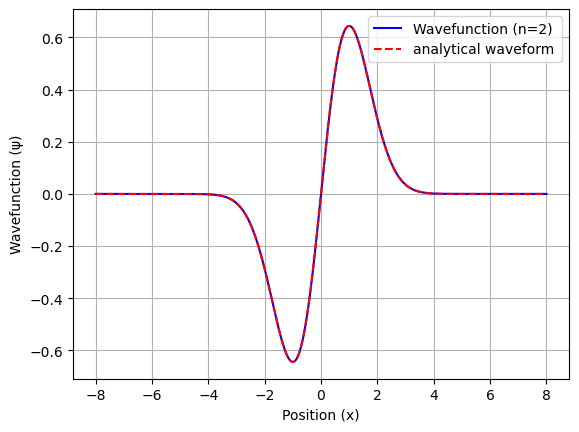

In [38]:
state_number = 1
x, phi, energy, exact_energy, analytical_phi, Qn = solve_harmonic_oscilator(8,900,state_number)  
plt.plot(x, phi, label=f'Wavefunction (n={state_number+1}) ' , color='blue')
plt.plot(x, analytical_phi, label="analytical waveform", color='red', linestyle = '--')
plt.xlabel('Position (x)')
plt.ylabel('Wavefunction (ψ)')
plt.legend()
plt.grid(True)
plt.show()

### Numerical energy and analytical energy

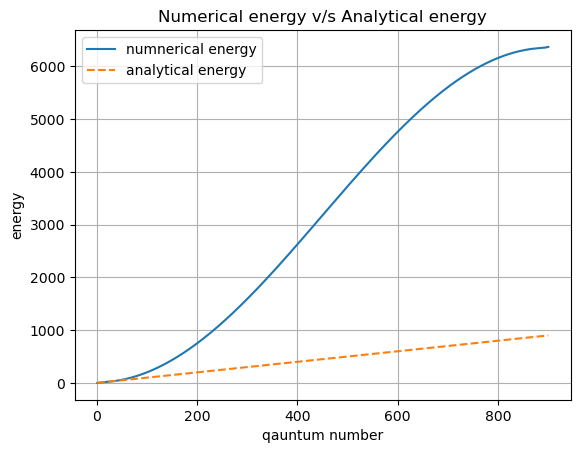

In [7]:
plt.plot(Qn, energy, label = 'numnerical energy')
plt.plot(Qn, exact_energy, label = 'analytical energy', linestyle = '--')
plt.xlabel("qauntum number")
plt.ylabel('energy')
plt.title("Numerical energy v/s Analytical energy")
plt.legend()
plt.grid()
plt.show()

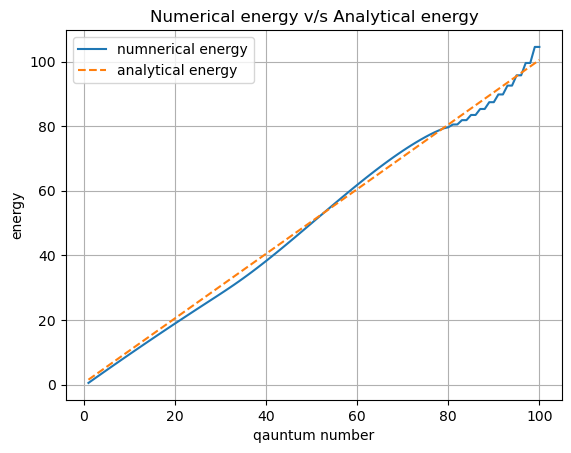

We can see clearly that the numerical and analytical energies agree reasonably well for the lower states, but diverges significantly for higher states.
This happens because:
as the quantum number increases
1. the wavefunction oscillates more rapidly.
2. the number of nodes increases.
3. the spatial grid needs to resole increasingly small wavelength. 

### Solving Using Shooting Method

In [49]:
from rk4 import RK4

In [113]:
m = 1
n = int(input('enter the state number'))
if n == 0:
    p = 'ground state'
else:
    p = f'state = {n}'
L = 10
h_bar = 1
E = 1/2 + n



In [114]:
def function(S, x):
    psi, z = S
    d_psi = z
    
    V = 0.5*x**2
    d_z = -(2*m*(E-V)/h_bar**2)*psi
    return np.array([d_psi, d_z])

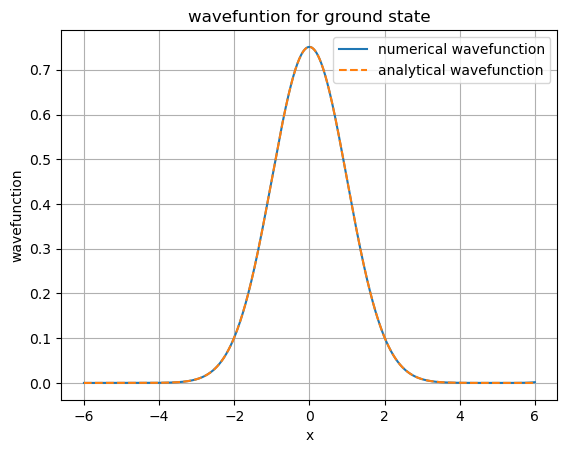

In [115]:
S0 = [0,1]  #initial value
x = np.linspace(-6,6, 1000) 
dx = x[1]-x[0]
solution = RK4(function, S0, x)
psi = solution[:,0]
sum = np.sum(np.abs(psi)**2)*dx
phi_norm = psi/np.sqrt(sum)
if phi_norm[np.argmax(np.abs(phi_norm))] < 0:
    phi_norm = -phi_norm
analytical_phi = eval_hermite(n, x)*np.exp(-x**2/2)/(np.sqrt(2**n*factorial(n)*np.pi**(1/2)))

plt.plot(x, phi_norm, label = 'numerical wavefunction')
plt.plot(x,analytical_phi, label = 'analytical wavefunction', linestyle = '--')
plt.title(f'wavefuntion for {p}')
plt.xlabel('x')
plt.ylabel('wavefunction')
plt.legend()
plt.grid()
plt.show()

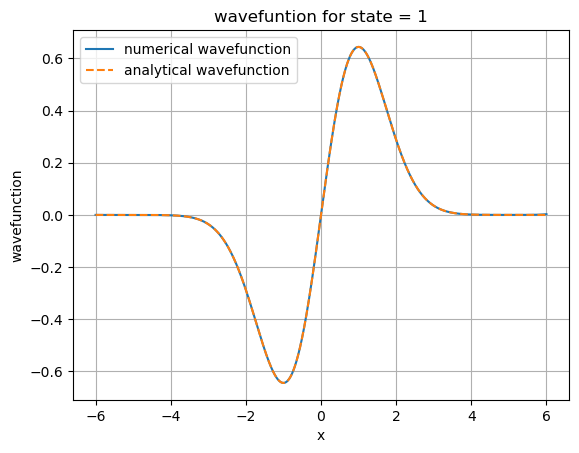

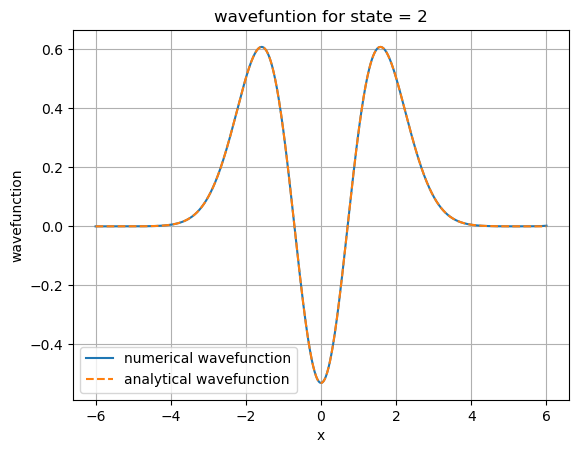